In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [18]:
df = pd.read_csv("csv/dataset_completo.csv")
# Eliminar todas las columnas comp_*
columnas_comp = [
    c for c in df.columns
    if c.startswith("comp_")
]

df_sin_comp = df.drop(columns=columnas_comp)

print(df_sin_comp.shape)
print(df_sin_comp.columns.tolist())

df_sin_comp.to_csv("csv/dataset_sin_comp.csv", index=False)

(17991, 36)
['img_original', 'img_recodificada', 'metodo', 'formato', 'calidad', 'orig_rango', 'orig_std', 'orig_michelson', 'orig_hf', 'orig_lf', 'orig_hlfr', 'orig_edges_s1', 'orig_edges_s2', 'orig_edges_s3', 'orig_grad_mean', 'orig_grad_std', 'orig_glcm_contrast', 'orig_glcm_hom', 'orig_glcm_energy', 'orig_glcm_corr', 'orig_sat_mean', 'orig_sat_var', 'orig_hist', 'orig_hist_norm', 'orig_hist_bins', 'orig_hist_entropy', 'orig_hist_std', 'orig_hist_mean', 'orig_hist_min', 'orig_hist_max', 'orig_hist_skew', 'orig_hist_kurt', 'ms_ssim', 'lpips_raw', 'lpips_norm', 'combinado']


In [19]:
df = pd.read_csv("csv/dataset_sin_comp.csv")

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17991 entries, 0 to 17990
Data columns (total 36 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   img_original        17991 non-null  object 
 1   img_recodificada    17991 non-null  object 
 2   metodo              17991 non-null  object 
 3   formato             17991 non-null  object 
 4   calidad             17991 non-null  int64  
 5   orig_rango          17991 non-null  float64
 6   orig_std            17991 non-null  float64
 7   orig_michelson      17991 non-null  float64
 8   orig_hf             17991 non-null  float64
 9   orig_lf             17991 non-null  float64
 10  orig_hlfr           17991 non-null  float64
 11  orig_edges_s1       17991 non-null  float64
 12  orig_edges_s2       17991 non-null  float64
 13  orig_edges_s3       17991 non-null  float64
 14  orig_grad_mean      17991 non-null  float64
 15  orig_grad_std       17991 non-null  float64
 16  orig

# Target: combinado

In [12]:
plt.style.use("dark_background")
df = pd.read_csv("csv/dataset_sin_comp.csv")

# ── Estadísticas del target ──
print("=" * 50)
print("TARGET: combinado")
print("=" * 50)
print(df["combinado"].describe())
print(f"\nSkewness:  {df['combinado'].skew():.4f}")
print(f"Kurtosis:  {df['combinado'].kurt():.4f}")

# ── Estadísticas generales numéricas ──
cols_numericas = df.select_dtypes(include="float64").columns.tolist()
print(f"\nTotal features numéricas: {len(cols_numericas)}")
df[cols_numericas].describe().T.round(4)

TARGET: combinado
count    17991.000000
mean         0.966575
std          0.044059
min          0.720002
25%          0.952576
50%          0.984255
75%          0.998749
max          1.000000
Name: combinado, dtype: float64

Skewness:  -1.6912
Kurtosis:  2.3808

Total features numéricas: 28


,count,mean,std,min,25%,50%,75%,max
orig_rango,17991.0,9.737000e-01,8.730000e-02,0.0000,9.891000e-01,9.994000e-01,1.000000e+00,1.000000e+00
orig_std,17991.0,2.356000e-01,6.090000e-02,0.0000,1.989000e-01,2.375000e-01,2.733000e-01,4.804000e-01
orig_michelson,17991.0,8.488000e-01,1.386000e-01,0.0000,7.968000e-01,8.884000e-01,9.449000e-01,1.000000e+00
orig_hf,17991.0,1.067945e+09,9.769939e+09,0.0000,2.707952e+07,1.439193e+08,2.955548e+08,2.826897e+11
orig_lf,17991.0,5.622716e+11,3.461020e+12,0.0000,6.881009e+09,2.317151e+10,1.250953e+11,5.619489e+13
orig_hlfr,17991.0,7.000000e-03,1.000000e-02,0.0000,1.500000e-03,3.400000e-03,8.100000e-03,1.609000e-01
orig_edges_s1,17991.0,9.790000e-02,5.890000e-02,0.0000,5.350000e-02,8.420000e-02,1.284000e-01,3.488000e-01
orig_edges_s2,17991.0,4.970000e-02,2.730000e-02,0.0000,2.940000e-02,4.430000e-02,6.460000e-02,1.824000e-01
orig_edges_s3,17991.0,3.000000e-02,1.580000e-02,0.0000,1.850000e-02,2.730000e-02,3.890000e-02,1.036000e-01
orig_grad_mean,17991.0,2.168000e-01,1.290000e-01,0.0000,1.219000e-01,1.813000e-01,2.827000e-01,9.369000e-01


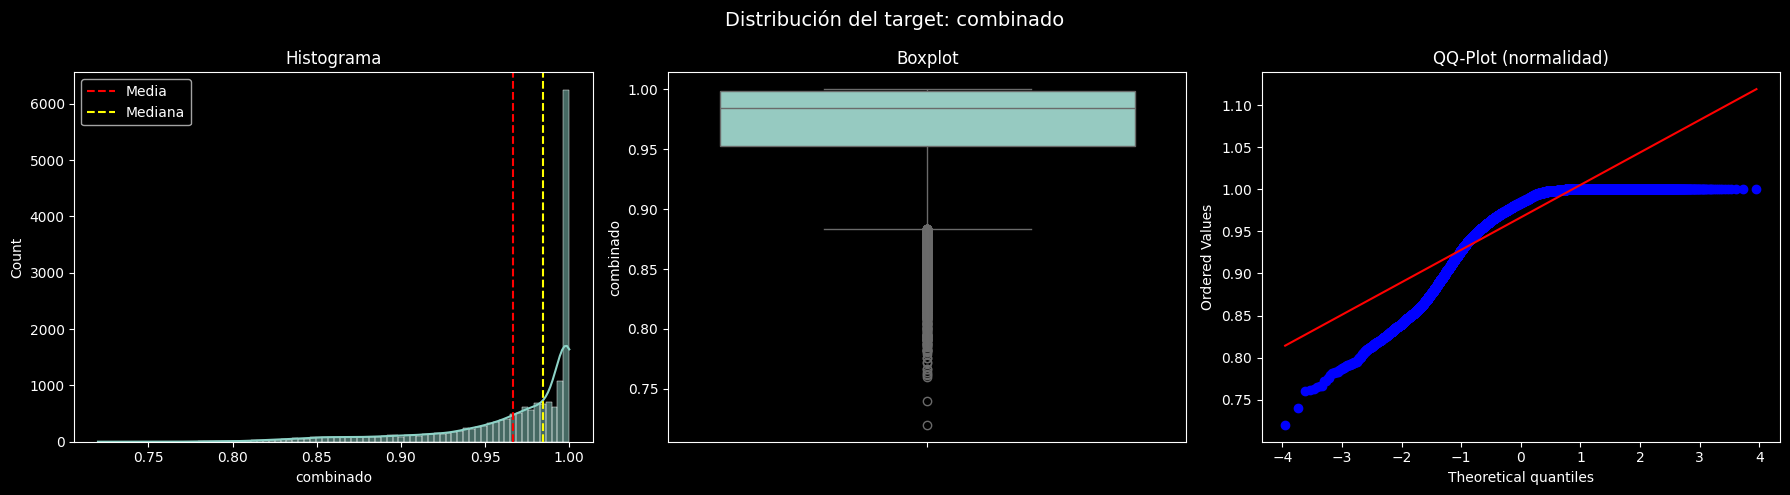

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Distribución del target: combinado", fontsize=14)

# Histograma + KDE
sns.histplot(df["combinado"], bins=80, kde=True, ax=axes[0])
axes[0].set_title("Histograma")
axes[0].axvline(df["combinado"].mean(), color="red", linestyle="--", label="Media")
axes[0].axvline(df["combinado"].median(), color="yellow", linestyle="--", label="Mediana")
axes[0].legend()

# Boxplot
sns.boxplot(y=df["combinado"], ax=axes[1])
axes[1].set_title("Boxplot")

# QQ-Plot — ¿es normal?
stats.probplot(df["combinado"], dist="norm", plot=axes[2])
axes[2].set_title("QQ-Plot (normalidad)")

plt.tight_layout()
plt.show()

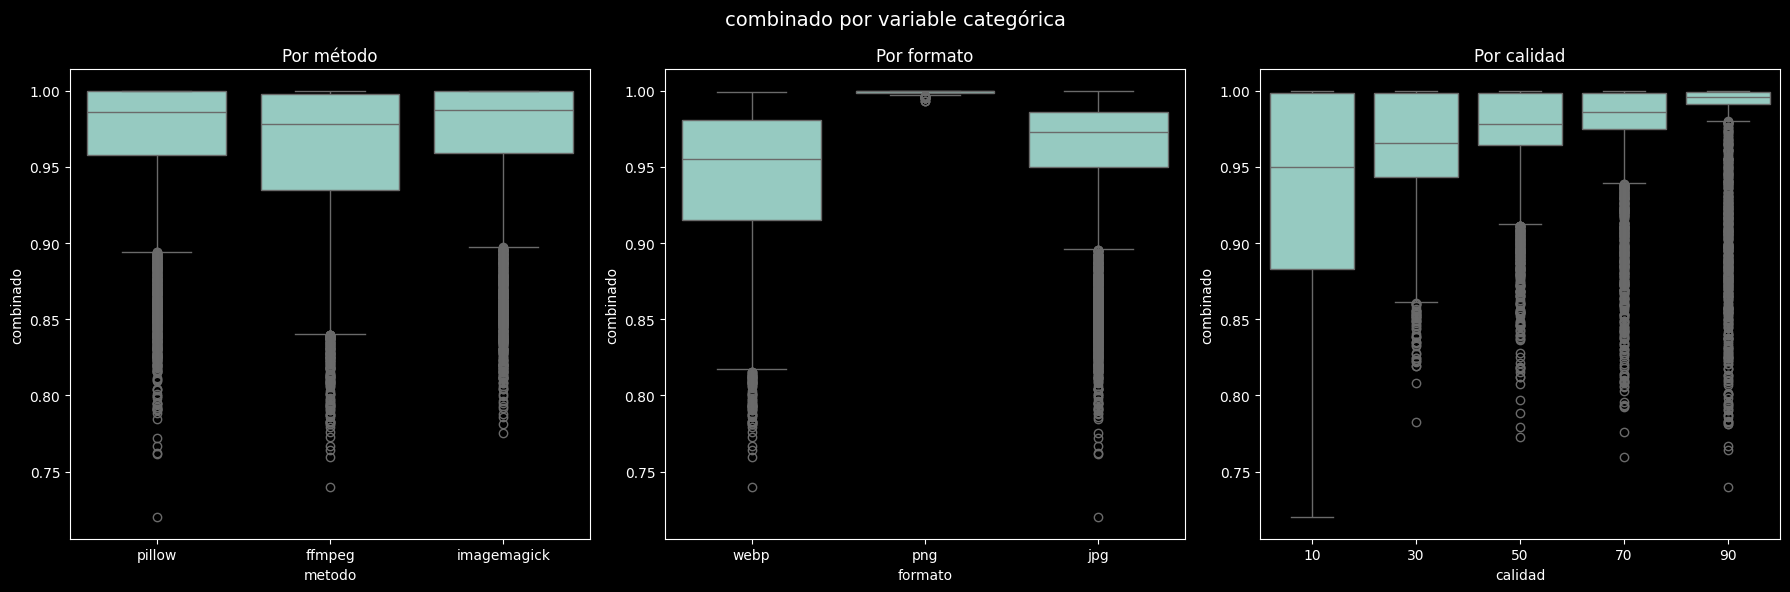


Media combinado por método:
metodo
ffmpeg         0.9598
imagemagick    0.9706
pillow         0.9693
Name: combinado, dtype: float64

Media combinado por formato:
formato
jpg     0.9567
png     0.9994
webp    0.9436
Name: combinado, dtype: float64

Media combinado por calidad:
calidad
10    0.9360
30    0.9632
50    0.9726
70    0.9771
90    0.9833
Name: combinado, dtype: float64


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("combinado por variable categórica", fontsize=14)

# Por método
sns.boxplot(data=df, x="metodo", y="combinado", ax=axes[0])
axes[0].set_title("Por método")

# Por formato
sns.boxplot(data=df, x="formato", y="combinado", ax=axes[1])
axes[1].set_title("Por formato")

# Por calidad
sns.boxplot(data=df, x="calidad", y="combinado", ax=axes[2])
axes[2].set_title("Por calidad")

plt.tight_layout()
plt.show()

# Medias por grupo
print("\nMedia combinado por método:")
print(df.groupby("metodo")["combinado"].mean().round(4))

print("\nMedia combinado por formato:")
print(df.groupby("formato")["combinado"].mean().round(4))

print("\nMedia combinado por calidad:")
print(df.groupby("calidad")["combinado"].mean().round(4))

El target tiene una distribución fuertemente sesgada a la izquierda (skewness = -1.69) — la mayoría de valores se concentran cerca de 1.0 (alta calidad), con una cola larga hacia valores bajos. Esto es esperado: la mayoría de recodificaciones con calidad media-alta preservan bien la imagen. El QQ-Plot confirma que no es normal — hay desviaciones importantes en ambos extremos.
Esto tiene implicaciones para el modelo: un regresor que prediga siempre ~0.97 tendría un error aparentemente bajo. Hay que usar métricas como MAE y R² en lugar de solo MSE.

# Correlaciones con el target

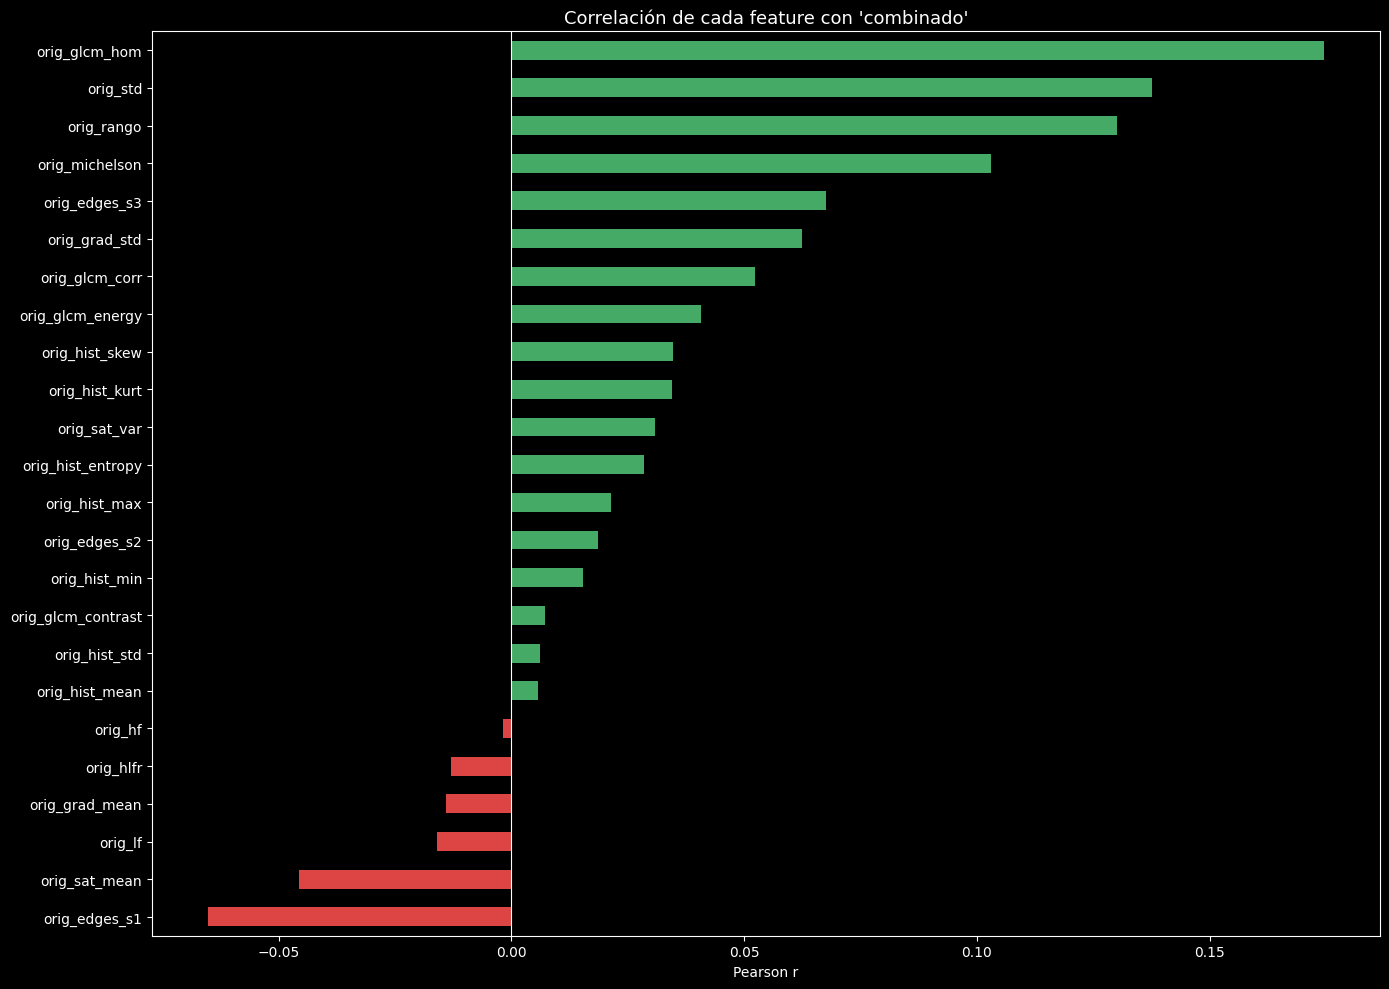


Top 10 más correlacionadas:
orig_glcm_hom       0.174569
orig_std            0.137686
orig_rango          0.130100
orig_michelson      0.103122
orig_edges_s3       0.067636
orig_edges_s1       0.065186
orig_grad_std       0.062344
orig_glcm_corr      0.052297
orig_sat_mean       0.045620
orig_glcm_energy    0.040748
dtype: float64


In [15]:
# Solo columnas numéricas float64
feat_cols = [c for c in df.select_dtypes("float64").columns
             if c not in ["ms_ssim", "lpips_raw", "lpips_norm", "combinado"]]

correlaciones = df[feat_cols].corrwith(df["combinado"]).sort_values()

plt.figure(figsize=(14, 10))
correlaciones.plot(kind="barh", color=[
    "#DD4444" if v < 0 else "#44AA66" for v in correlaciones
])
plt.axvline(0, color="white", linewidth=0.8)
plt.title("Correlación de cada feature con 'combinado'", fontsize=13)
plt.xlabel("Pearson r")
plt.tight_layout()
plt.show()

print("\nTop 10 más correlacionadas:")
print(correlaciones.abs().sort_values(ascending=False).head(10))

Las correlaciones individuales son bajas (máximo 0.17) pero esto es normal en problemas perceptuales complejos. Lo importante es el patrón:
Features más útiles:

orig_glcm_hom (r=0.175) — homogeneidad de textura: imágenes más uniformes se comprimen mejor
orig_std (r=0.138) — desviación estándar de brillo
orig_rango (r=0.130) — rango dinámico
orig_michelson (r=0.103) — contraste global

Features con correlación negativa (pequeña):

orig_edges_s1, orig_sat_mean — imágenes con muchos bordes finos y alta saturación sufren más degradación

Features prácticamente inútiles para el modelo:

orig_hist_mean — varianza casi cero (todos los valores son 0.0039)
orig_hist_skew, orig_hist_kurt — valores prácticamente constantes

# Heatmap 

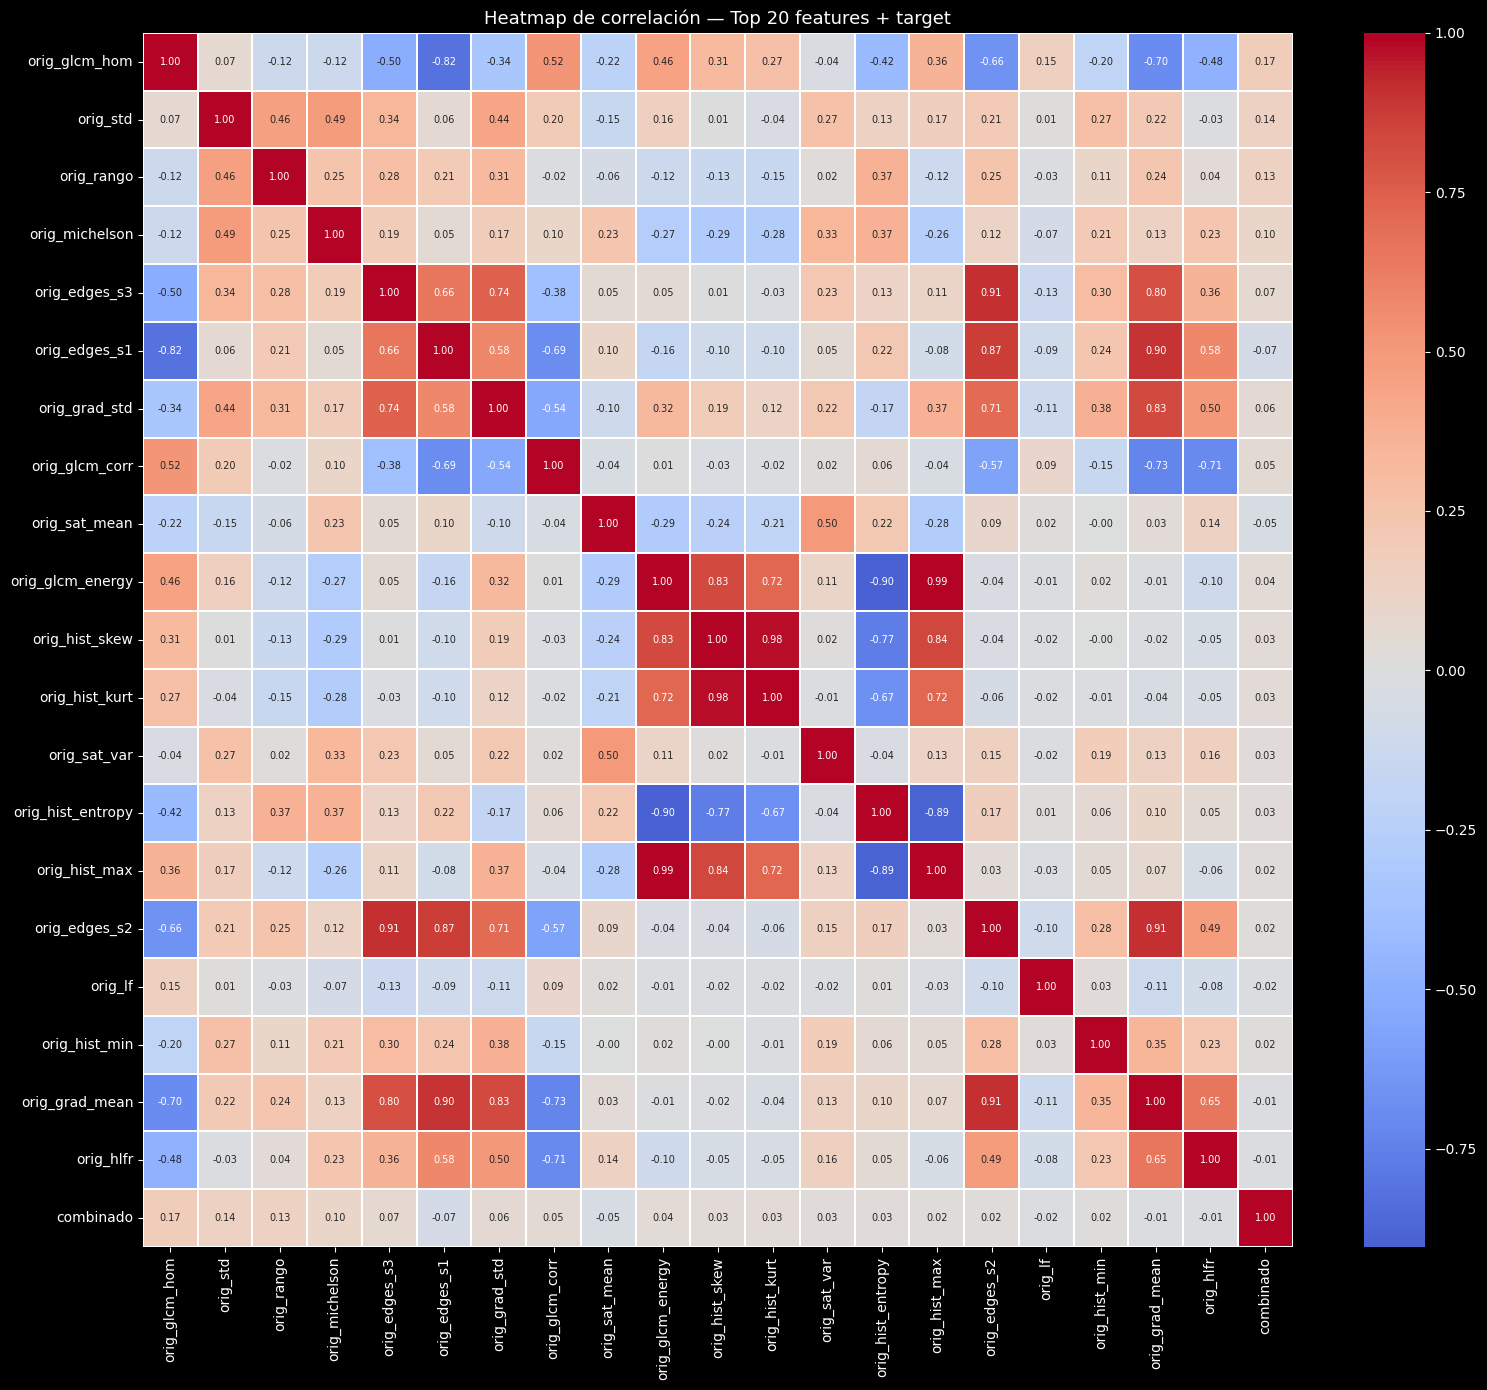

In [16]:
# Seleccionar features más relevantes para no saturar el heatmap
top_feats = correlaciones.abs().sort_values(ascending=False).head(20).index.tolist()
top_feats += ["combinado"]

corr_matrix = df[top_feats].corr()

plt.figure(figsize=(16, 14))
sns.heatmap(
    corr_matrix,
    annot=True, fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.3,
    annot_kws={"size": 7}
)
plt.title("Heatmap de correlación — Top 20 features + target", fontsize=13)
plt.tight_layout()
plt.show()

Hay multicolinealidad severa entre varios grupos:

orig_glcm_energy ↔ orig_hist_skew ↔ orig_hist_kurt (r > 0.83)
orig_edges_s1 ↔ orig_edges_s2 ↔ orig_grad_mean (r > 0.87)
orig_hist_entropy ↔ orig_hist_max (r = -0.89)

Esto significa que hay features redundantes.

# Distribuciones 

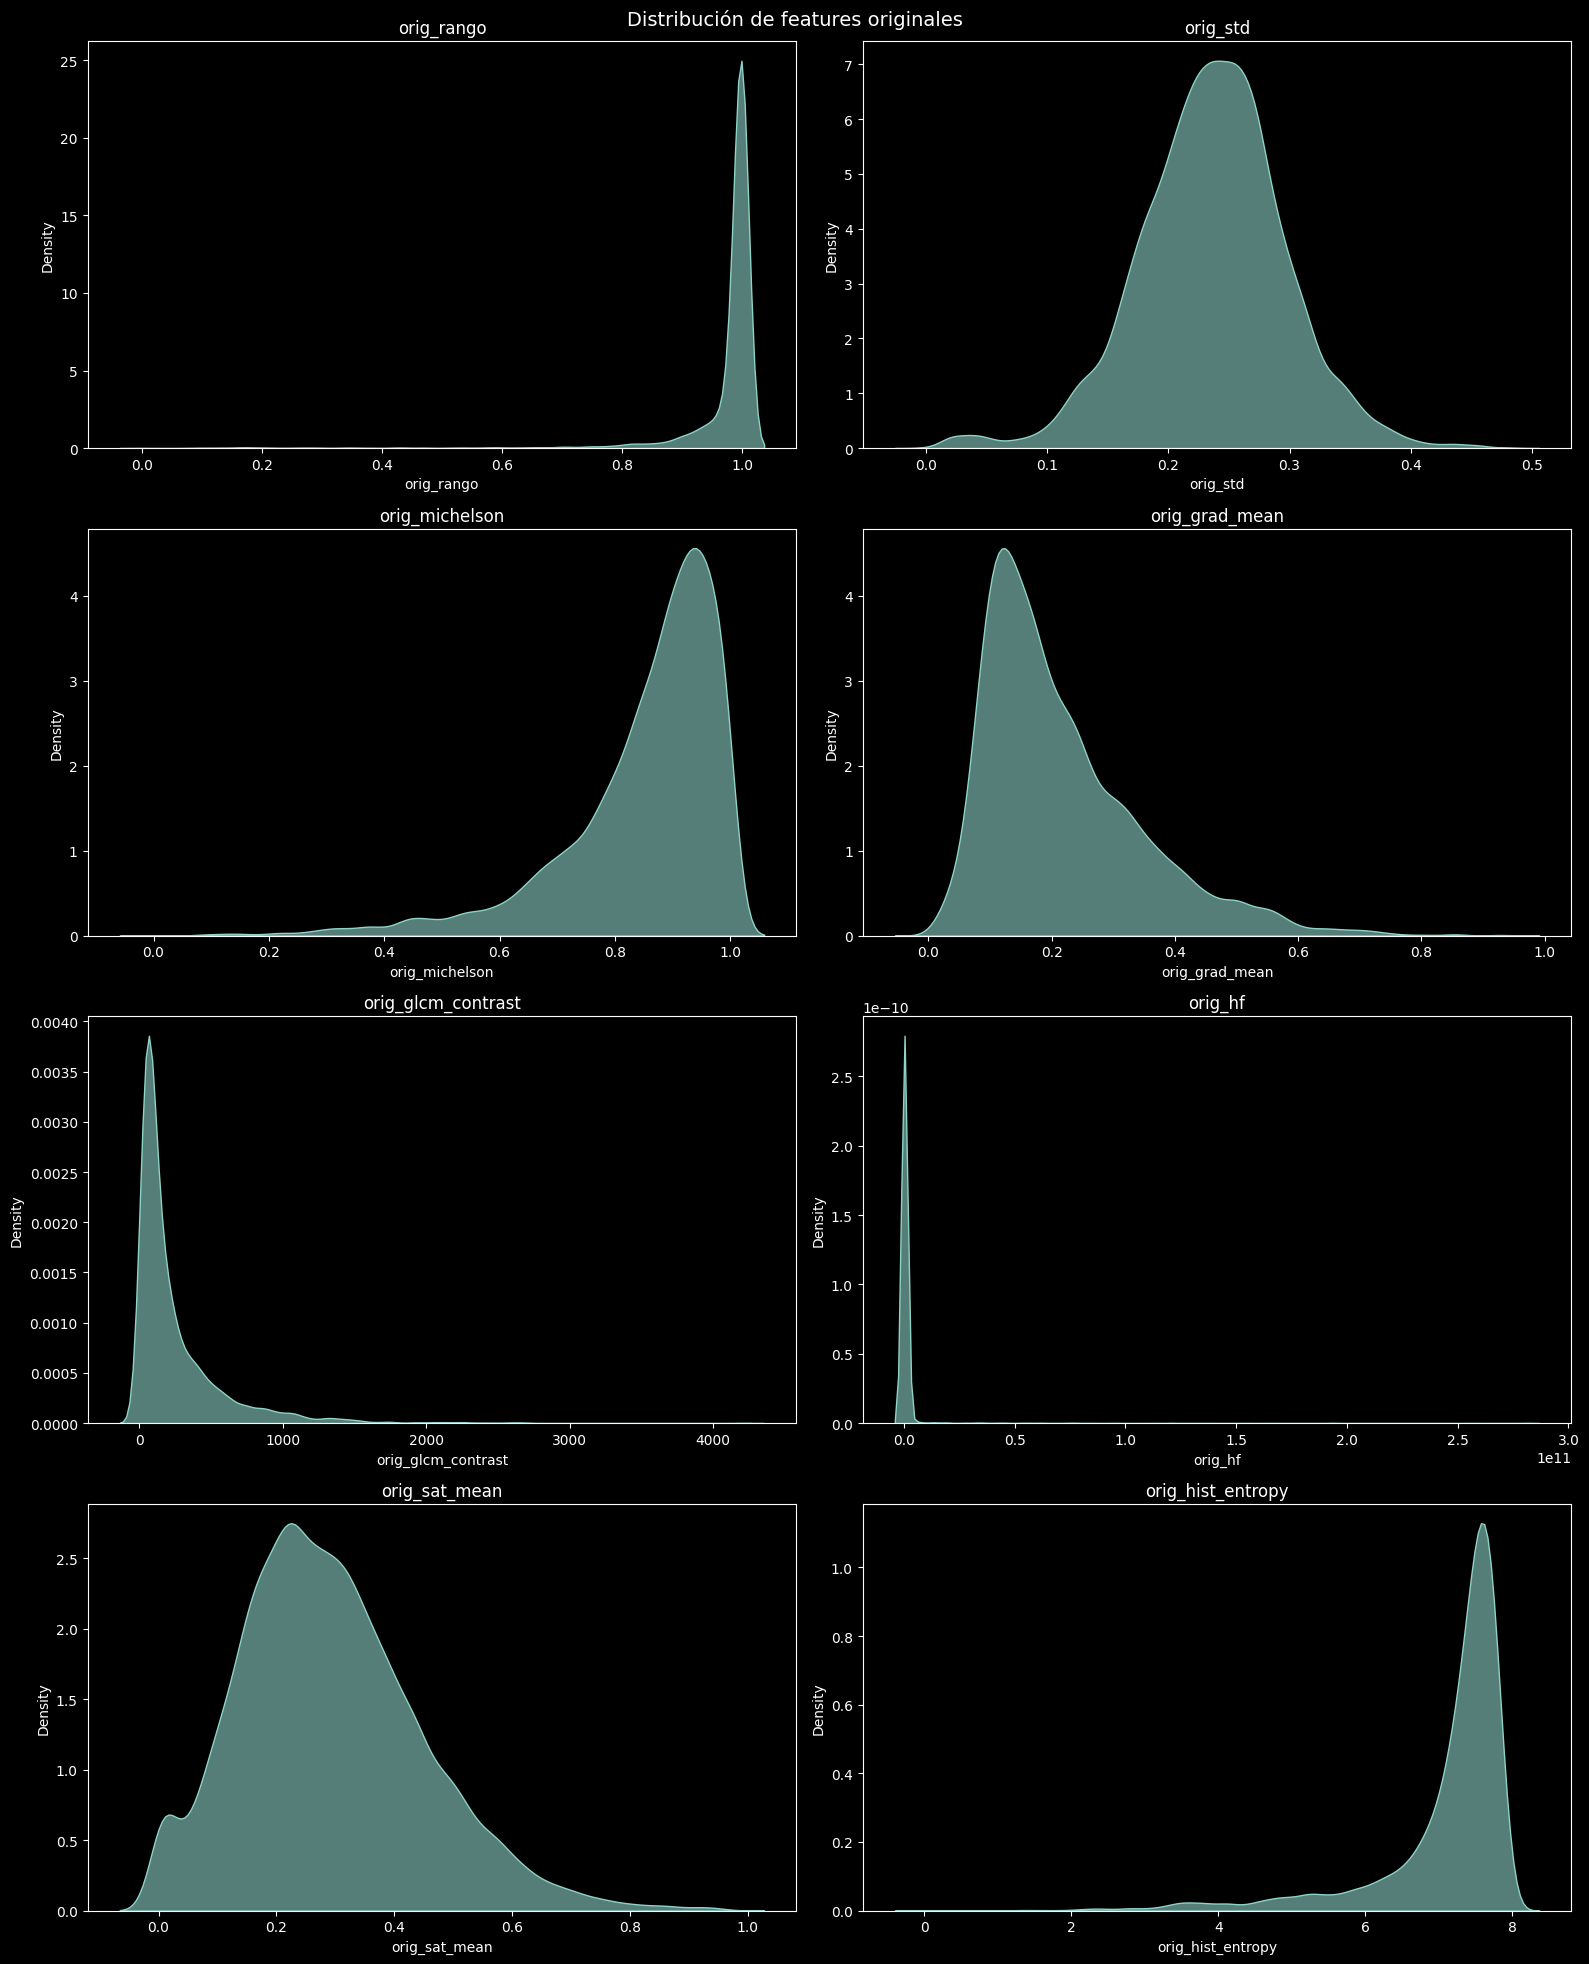

In [17]:
# Reemplazar por distribución de features originales solamente
features_ver = [
    "orig_rango", "orig_std", "orig_michelson", "orig_grad_mean",
    "orig_glcm_contrast", "orig_hf", "orig_sat_mean", "orig_hist_entropy"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
fig.suptitle("Distribución de features originales", fontsize=14)

for ax, f in zip(axes.flat, features_ver):
    sns.kdeplot(df[f], ax=ax, fill=True, alpha=0.6)
    ax.set_title(f)

plt.tight_layout()
plt.show()

orig_hf y orig_lf tienen escalas enormes (1e+11) — necesitan normalización obligatoria
orig_glcm_contrast tiene cola muy larga — candidata a transformación logarítmica
orig_rango está acumulada en 1.0 — poca variabilidad útil
orig_hist_mean es constante — eliminar

# Outliers 

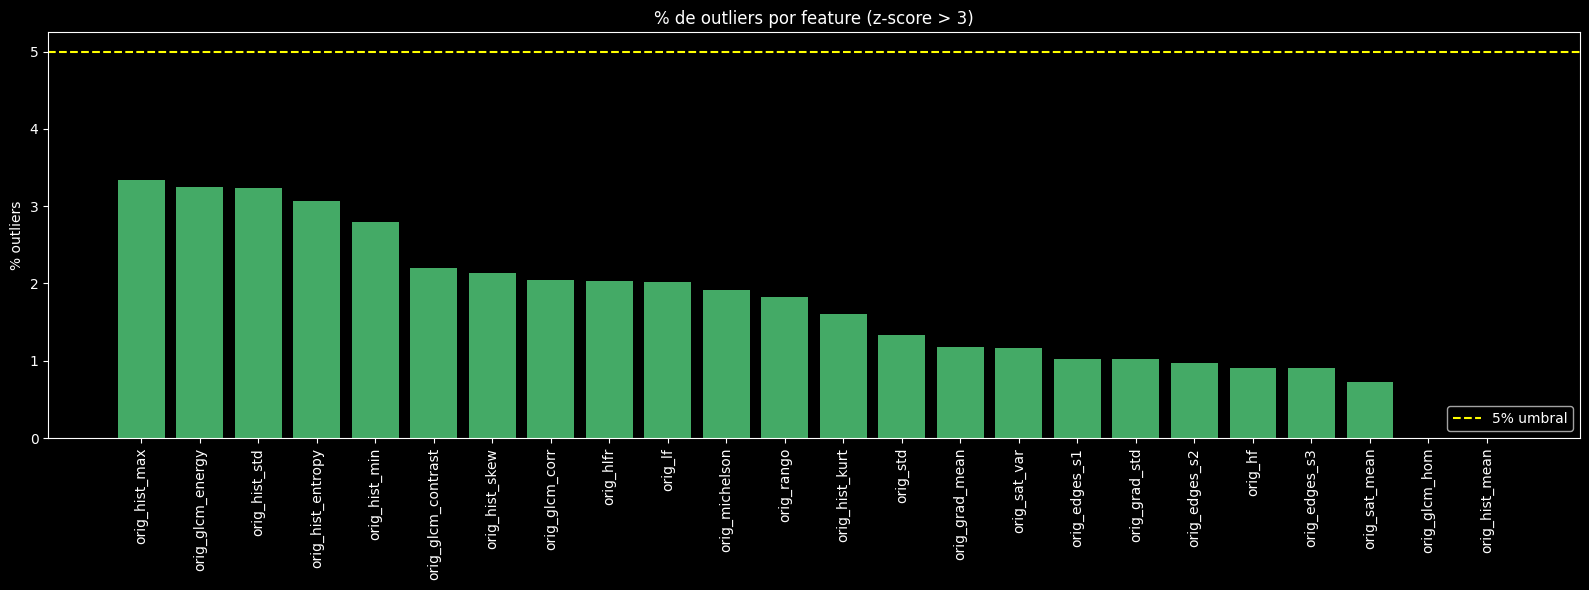


Features con más del 5% de outliers:
Empty DataFrame
Columns: [feature, n_outliers, pct]
Index: []


In [18]:
# Excluir columnas objeto y targets — solo features numéricas de entrada
feat_cols_num = [c for c in df.select_dtypes("float64").columns
                 if c not in ["ms_ssim", "lpips_raw", "lpips_norm", "combinado"]]

outliers_resumen = []

for col in feat_cols_num:
    z = np.abs(stats.zscore(df[col]))
    n_outliers = (z > 3).sum()
    outliers_resumen.append({"feature": col, "n_outliers": n_outliers,
                             "pct": round(n_outliers / len(df) * 100, 2)})

df_out = pd.DataFrame(outliers_resumen).sort_values("n_outliers", ascending=False)

plt.figure(figsize=(16, 6))
plt.bar(df_out["feature"], df_out["pct"],
        color=["#DD4444" if v > 5 else "#44AA66" for v in df_out["pct"]])
plt.xticks(rotation=90)
plt.axhline(5, color="yellow", linestyle="--", label="5% umbral")
plt.title("% de outliers por feature (z-score > 3)")
plt.ylabel("% outliers")
plt.legend()
plt.tight_layout()
plt.show()

print("\nFeatures con más del 5% de outliers:")
print(df_out[df_out["pct"] > 5])

Ninguna feature supera el 5% — el dataset está limpio. El máximo es orig_hist_max con ~3.4%, aceptable.

# Limpiar el dataset

# Eliminar columnas inútiles

In [20]:
# Columnas a eliminar
cols_eliminar = [
    # Varianza cero o casi cero
    "orig_hist_mean",
    "orig_hist_skew",
    "orig_hist_kurt",
    # Listas — no usables directamente como features
    "orig_hist",
    "orig_hist_norm",
    "orig_hist_bins",
    # Rutas — no son features
    "img_original",
    "img_recodificada",
    # Componentes del target — no deben entrar como features
    "ms_ssim",
    "lpips_raw",
    "lpips_norm",
]

df_clean = df.drop(columns=cols_eliminar)

print(f"Columnas originales: {df.shape[1]}")
print(f"Columnas después de limpieza: {df_clean.shape[1]}")
print(f"\nColumnas restantes:\n{df_clean.columns.tolist()}")

Columnas originales: 36
Columnas después de limpieza: 25

Columnas restantes:
['metodo', 'formato', 'calidad', 'orig_rango', 'orig_std', 'orig_michelson', 'orig_hf', 'orig_lf', 'orig_hlfr', 'orig_edges_s1', 'orig_edges_s2', 'orig_edges_s3', 'orig_grad_mean', 'orig_grad_std', 'orig_glcm_contrast', 'orig_glcm_hom', 'orig_glcm_energy', 'orig_glcm_corr', 'orig_sat_mean', 'orig_sat_var', 'orig_hist_entropy', 'orig_hist_std', 'orig_hist_min', 'orig_hist_max', 'combinado']


# Eliminar multicolinealidad alta

In [21]:
from scipy.stats import pearsonr

# Features numéricas sin el target ni categóricas
feat_num = [c for c in df_clean.select_dtypes("float64").columns
            if c != "combinado"]

# Calcular matriz de correlación
corr_matrix = df_clean[feat_num].corr().abs()

# Detectar pares con correlación > 0.85
pares_alta_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if corr_matrix.iloc[i, j] > 0.85:
            pares_alta_corr.append({
                "feature_1": corr_matrix.columns[i],
                "feature_2": corr_matrix.columns[j],
                "correlacion": round(corr_matrix.iloc[i, j], 4)
            })

df_corr_alta = pd.DataFrame(pares_alta_corr).sort_values("correlacion", ascending=False)
print("Pares con correlación > 0.85:")
print(df_corr_alta.to_string(index=False))

Pares con correlación > 0.85:
        feature_1          feature_2  correlacion
 orig_glcm_energy      orig_hist_max       0.9916
 orig_glcm_energy      orig_hist_std       0.9878
    orig_hist_std      orig_hist_max       0.9871
orig_hist_entropy      orig_hist_std       0.9477
    orig_edges_s2     orig_grad_mean       0.9077
    orig_edges_s2      orig_edges_s3       0.9071
 orig_glcm_energy  orig_hist_entropy       0.9045
    orig_edges_s1     orig_grad_mean       0.9020
orig_hist_entropy      orig_hist_max       0.8901
   orig_grad_mean orig_glcm_contrast       0.8713
    orig_edges_s1      orig_edges_s2       0.8697


In [22]:
# Eliminar una de cada par redundante
# Criterio: quedarse con la que tiene mayor correlación con el target
cols_redundantes = []

for _, row in df_corr_alta.iterrows():
    f1, f2 = row["feature_1"], row["feature_2"]

    if f1 in cols_redundantes or f2 in cols_redundantes:
        continue

    r1 = abs(df_clean[f1].corr(df_clean["combinado"]))
    r2 = abs(df_clean[f2].corr(df_clean["combinado"]))

    # Eliminar la que menos correlaciona con el target
    eliminar = f2 if r1 >= r2 else f1
    cols_redundantes.append(eliminar)
    print(f"  {f1} (r={r1:.4f}) vs {f2} (r={r2:.4f}) → eliminar: {eliminar}")

df_clean = df_clean.drop(columns=cols_redundantes)
print(f"\nColumnas eliminadas por multicolinealidad: {len(cols_redundantes)}")
print(f"Columnas restantes: {df_clean.shape[1]}")

  orig_glcm_energy (r=0.0407) vs orig_hist_max (r=0.0215) → eliminar: orig_hist_max
  orig_glcm_energy (r=0.0407) vs orig_hist_std (r=0.0062) → eliminar: orig_hist_std
  orig_edges_s2 (r=0.0186) vs orig_grad_mean (r=0.0141) → eliminar: orig_grad_mean
  orig_edges_s2 (r=0.0186) vs orig_edges_s3 (r=0.0676) → eliminar: orig_edges_s2
  orig_glcm_energy (r=0.0407) vs orig_hist_entropy (r=0.0286) → eliminar: orig_hist_entropy

Columnas eliminadas por multicolinealidad: 5
Columnas restantes: 20


# Transformación logarítmica

In [23]:
import numpy as np

cols_log = ["orig_hf", "orig_lf", "orig_glcm_contrast"]

for col in cols_log:
    df_clean[f"{col}_log"] = np.log1p(df_clean[col])
    df_clean = df_clean.drop(columns=[col])
    print(f"✅ {col} → {col}_log")

print(f"\nShape después de transformación log: {df_clean.shape}")

✅ orig_hf → orig_hf_log
✅ orig_lf → orig_lf_log
✅ orig_glcm_contrast → orig_glcm_contrast_log

Shape después de transformación log: (17991, 20)


# Encoding de variables categóricas

In [24]:
# Ver distribución antes de encoding
print("Valores únicos por categórica:")
for col in ["metodo", "formato"]:
    print(f"  {col}: {df_clean[col].unique()}")

# One-Hot Encoding
df_clean = pd.get_dummies(df_clean, columns=["metodo", "formato"], dtype=int)

print(f"\nColumnas después de encoding: {df_clean.shape[1]}")
print("Nuevas columnas:", [c for c in df_clean.columns if "metodo_" in c or "formato_" in c])

Valores únicos por categórica:
  metodo: ['pillow' 'ffmpeg' 'imagemagick']
  formato: ['webp' 'png' 'jpg']

Columnas después de encoding: 24
Nuevas columnas: ['metodo_ffmpeg', 'metodo_imagemagick', 'metodo_pillow', 'formato_jpg', 'formato_png', 'formato_webp']


# Tratar outliers del target

Outliers en target (z>3): 312 (1.73%)


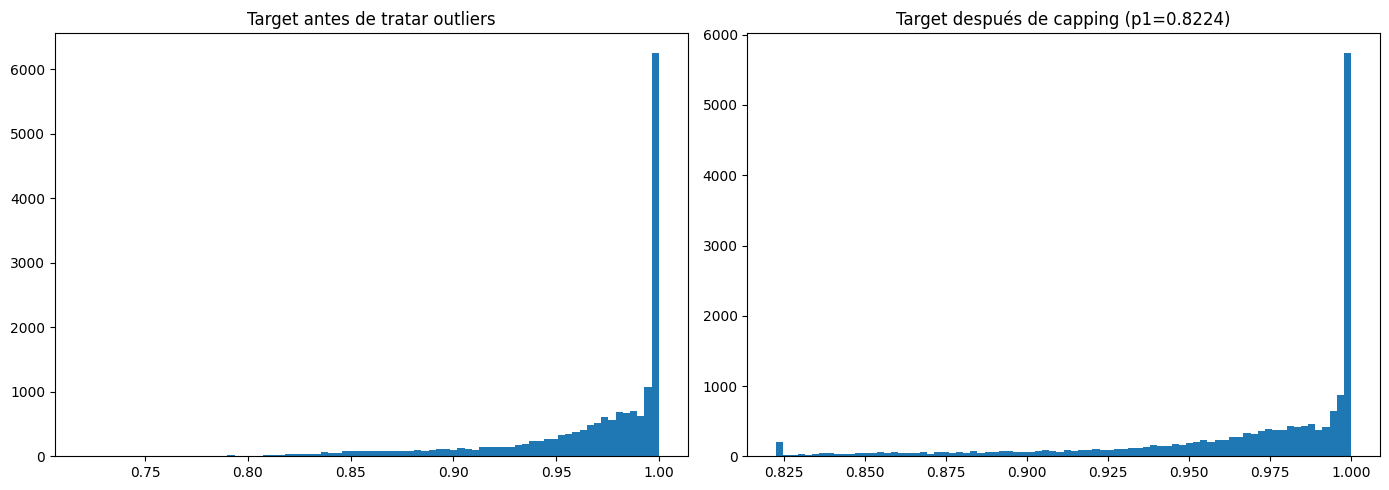


Nuevo rango target: [0.8224, 1.0000]


In [25]:
from scipy import stats

# Ver cuántos outliers tiene el target
z_target = np.abs(stats.zscore(df_clean["combinado"]))
outliers_target = (z_target > 3).sum()
print(f"Outliers en target (z>3): {outliers_target} ({outliers_target/len(df_clean)*100:.2f}%)")

# Visualizar antes y después
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_clean["combinado"], bins=80)
axes[0].set_title("Target antes de tratar outliers")

# Opción: capping en percentil 1 (no eliminar, solo acotar por abajo)
p01 = df_clean["combinado"].quantile(0.01)
df_clean["combinado"] = df_clean["combinado"].clip(lower=p01)

axes[1].hist(df_clean["combinado"], bins=80)
axes[1].set_title(f"Target después de capping (p1={p01:.4f})")

plt.tight_layout()
plt.show()

print(f"\nNuevo rango target: [{df_clean['combinado'].min():.4f}, {df_clean['combinado'].max():.4f}]")

# Normalización de features numéricas

In [26]:
from sklearn.preprocessing import StandardScaler

# Separar features numéricas del target y categóricas ya encodeadas
cols_escalar = [c for c in df_clean.select_dtypes("float64").columns
                if c != "combinado"]

print(f"Features a escalar: {len(cols_escalar)}")

scaler = StandardScaler()
df_clean[cols_escalar] = scaler.fit_transform(df_clean[cols_escalar])

print("✅ StandardScaler aplicado")
print(df_clean[cols_escalar].describe().round(3).T[["mean", "std", "min", "max"]])

Features a escalar: 16
✅ StandardScaler aplicado
                        mean  std     min     max
orig_rango               0.0  1.0 -11.153   0.301
orig_std                -0.0  1.0  -3.870   4.022
orig_michelson           0.0  1.0  -6.123   1.091
orig_hlfr                0.0  1.0  -0.693  15.324
orig_edges_s1           -0.0  1.0  -1.663   4.261
orig_edges_s3           -0.0  1.0  -1.902   4.671
orig_grad_std            0.0  1.0  -2.193   5.136
orig_glcm_hom           -0.0  1.0  -2.223   2.959
orig_glcm_energy        -0.0  1.0  -0.638   7.159
orig_glcm_corr          -0.0  1.0 -11.615   0.764
orig_sat_mean           -0.0  1.0  -1.874   4.300
orig_sat_var            -0.0  1.0  -1.580   5.641
orig_hist_min            0.0  1.0  -0.352  10.043
orig_hf_log              0.0  1.0  -9.835   4.312
orig_lf_log              0.0  1.0 -11.970   3.839
orig_glcm_contrast_log   0.0  1.0  -4.238   3.007


In [27]:
df_clean.to_csv("csv/dataset_preprocesado.csv", index=False)
print("Dataset preprocesado guardado en 'csv/dataset_preprocesado.csv'")

Dataset preprocesado guardado en 'csv/dataset_preprocesado.csv'


In [28]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17991 entries, 0 to 17990
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   calidad                 17991 non-null  int64  
 1   orig_rango              17991 non-null  float64
 2   orig_std                17991 non-null  float64
 3   orig_michelson          17991 non-null  float64
 4   orig_hlfr               17991 non-null  float64
 5   orig_edges_s1           17991 non-null  float64
 6   orig_edges_s3           17991 non-null  float64
 7   orig_grad_std           17991 non-null  float64
 8   orig_glcm_hom           17991 non-null  float64
 9   orig_glcm_energy        17991 non-null  float64
 10  orig_glcm_corr          17991 non-null  float64
 11  orig_sat_mean           17991 non-null  float64
 12  orig_sat_var            17991 non-null  float64
 13  orig_hist_min           17991 non-null  float64
 14  combinado               17991 non-null

# Split train/val/test y guardado

In [30]:
from sklearn.model_selection import train_test_split

# Separar features y target
X = df_clean.drop(columns=["combinado"])
y = df_clean["combinado"]

print(f"Features: {X.shape[1]}")
print(f"Muestras: {X.shape[0]}")

# Split 70% train / 15% val / 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print(f"\nTrain: {X_train.shape[0]} muestras ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Val:   {X_val.shape[0]} muestras ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test:  {X_test.shape[0]} muestras ({X_test.shape[0]/len(X)*100:.1f}%)")

# Guardar
X_train.to_csv("csv/X_train.csv", index=False)
X_val.to_csv("csv/X_val.csv",   index=False)
X_test.to_csv("csv/X_test.csv",  index=False)
y_train.to_csv("csv/y_train.csv", index=False)
y_val.to_csv("csv/y_val.csv",   index=False)
y_test.to_csv("csv/y_test.csv",  index=False)

# Guardar scaler para inferencia futura
import joblib
joblib.dump(scaler, "csv/scaler.pkl")

print("\n✅ Datos guardados:")
print("   X_train, X_val, X_test")
print("   y_train, y_val, y_test")
print("   scaler.pkl")

Features: 23
Muestras: 17991

Train: 12593 muestras (70.0%)
Val:   2699 muestras (15.0%)
Test:  2699 muestras (15.0%)

✅ Datos guardados:
   X_train, X_val, X_test
   y_train, y_val, y_test
   scaler.pkl


# Verificación final

In [31]:
print("=" * 50)
print("RESUMEN FASE 3")
print("=" * 50)
print(f"Filas:          {df_clean.shape[0]}")
print(f"Features:       {X.shape[1]}")
print(f"Target rango:   [{y.min():.4f}, {y.max():.4f}]")
print(f"Target media:   {y.mean():.4f}")
print(f"Nulos:          {df_clean.isnull().sum().sum()}")
print(f"\nSplit:")
print(f"  Train: {len(X_train)}")
print(f"  Val:   {len(X_val)}")
print(f"  Test:  {len(X_test)}")
print(f"\nFeatures finales:")
print(X.columns.tolist())

RESUMEN FASE 3
Filas:          17991
Features:       23
Target rango:   [0.8224, 1.0000]
Target media:   0.9668
Nulos:          0

Split:
  Train: 12593
  Val:   2699
  Test:  2699

Features finales:
['calidad', 'orig_rango', 'orig_std', 'orig_michelson', 'orig_hlfr', 'orig_edges_s1', 'orig_edges_s3', 'orig_grad_std', 'orig_glcm_hom', 'orig_glcm_energy', 'orig_glcm_corr', 'orig_sat_mean', 'orig_sat_var', 'orig_hist_min', 'orig_hf_log', 'orig_lf_log', 'orig_glcm_contrast_log', 'metodo_ffmpeg', 'metodo_imagemagick', 'metodo_pillow', 'formato_jpg', 'formato_png', 'formato_webp']
